In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [73]:
x = np.random.normal(size = 100).reshape((20,5))

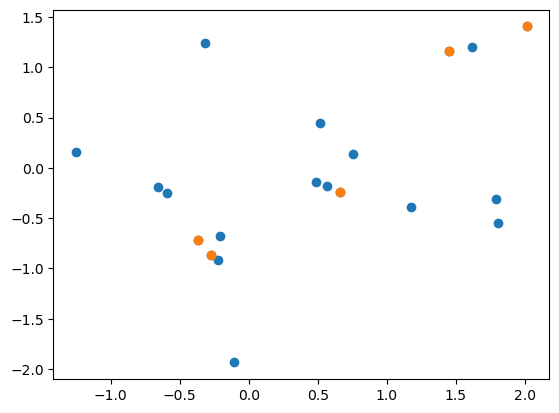

In [137]:
plt.scatter(x[:,0], x[:,1])
plt.scatter(basis[:,0], basis[:,1])

In [138]:
def argmax_det(i, x, basis_mask):
    
    det_list = []
    n = x.shape[0]
    for j in range(n):
        if basis_mask[j]:
            basis_ = np.concatenate([basis[np.arange(5) != i], x[j:(j+1),:]])
            det_list.append(np.abs(np.linalg.det(basis_)))
        else:
            det_list.append(0)
        
    return np.argmax(det_list)
        

In [156]:
basis = x[:5].copy()
basis_mask = np.arange(20) >= 5

In [157]:
for i in range(5):
    new_idx = argmax_det(i, x, basis_mask)
    print(i, new_idx)
    basis[i] = x[new_idx,:]
    basis_mask[new_idx] = False
    basis_mask[i] = True

0 11
1 16
2 10
3 8
4 3


In [158]:
basis_mask

array([ True,  True,  True, False,  True,  True,  True,  True, False,
        True, False, False,  True,  True,  True,  True, False,  True,
        True,  True])

In [159]:
np.abs(np.linalg.det(basis))

87.32437476233763

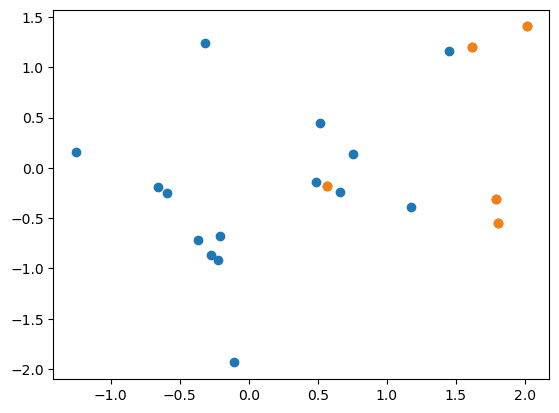

In [167]:
plt.scatter(x[:,0], x[:,1])
plt.scatter(basis[:,0], basis[:,1])

In [164]:
C = 1.1
e = 1
while e == 1:
    basis_start = basis.copy()
    for j in range(x.shape[0]):
        if basis_mask[i]:
            for i in range(5):
                basis_ = np.concatenate([basis[np.arange(5) != i], x[j:(j+1),:]])
                if (np.abs(np.linalg.det(basis_))) > C * (np.abs(np.linalg.det(basis))):
                    new_idx = j
                    basis[i] = x[new_idx,:]
                    basis_mask[new_idx] = False
                    basis_mask[i] = True
    if (basis_start == basis).all():
        e = 0

In [165]:
basis

array([[ 0.56711767, -0.17926779,  3.81677873, -1.39880996,  0.56001659],
       [ 1.8048306 , -0.55160102, -0.94089028, -0.9852609 , -0.45378903],
       [ 1.61967766,  1.19742348,  0.59167167, -1.77834865, -1.4625264 ],
       [ 1.78795073, -0.31305247, -0.02299071,  1.12913772, -1.54039318],
       [ 2.01405001,  1.40591152,  0.8725056 ,  1.52123256,  0.65824395]])

In [166]:
np.abs(np.linalg.det(basis))

122.84720240261588